# Sprint 16 — T23/T24: Generate Test Dataset & Run Inference

This notebook generates training + test data with all 10 anomaly types (4 original + 6 new) using the improved noise model (AR-1 momentum, local-window variance).

**Outputs:**
- `data/generated/train_welding_robot.csv` — 30 days, 4 robots, 100% normal (with improved noise)
- `data/generated/test_welding_robot.csv` — ~2000 cycles, 50% normal / 50% anomaly (10 types)
- `data/generated/test_labels.csv` — anomaly labels per cycle

**Full pipeline steps:**
1. Generate training data (30 days)
2. Generate test data (2000 cycles, 10 anomaly types)
3. Train MaskFormer on training data
4. Run inference on test data with phase-aware scoring
5. Evaluate — target ≥95% F1

In [ ]:
# %% Imports
from pathlib import Path
import sys

project_root = Path.cwd().parent.parent.resolve()
src_path = project_root / "anomaly-detection" / "src"
print(f"Src path: {src_path}")
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

from src.data_simulator.batch_generator import BatchGenerator
from src.data_simulator.writer import CSVWriter

print("All imports OK")

Project root: F:\DataImpact\TED-Hackathon-Agent\backend
All imports OK


## Step 1: Generate Training Data (30 days, 4 robots)

Uses the improved AR-1 momentum noise with local-window variance. All cycles are 100% normal.

In [2]:
# %% Generate training data
from datetime import datetime

gen = BatchGenerator(seed=42)
writer = CSVWriter(output_dir="F:/DataImpact/TED-Hackathon-Agent/data/generated")

print("Generating training data (30 days, 4 robots)...")
train_path, train_count = writer.write_train(
    gen,
    num_days=30,
    robots=[0, 1, 2, 3],
    start_date=datetime(2026, 3, 1),
)
print(f"Training data: {train_count:,} rows → {train_path}")

# Separate validation set: different date range, uses output_filename
val_path, val_count = writer.write_train(
    gen,
    num_days=7,
    robots=[0, 1, 2, 3],
    start_date=datetime(2026, 4, 1),
    output_filename="val_welding_robot.csv",
)
print(f"Validation data: {val_count:,} rows → {val_path}")


Generating training data (30 days, 4 robots)...
Training data: 10,413,311 rows → F:/DataImpact/TED-Hackathon-Agent/data/generated\train_welding_robot.csv
Validation data: 2,423,157 rows → F:/DataImpact/TED-Hackathon-Agent/data/generated\val_welding_robot.csv


## Step 2: Generate Test Data (2000 cycles, 10 anomaly types)

All 10 anomaly types are active. Uses `start_date=datetime(2026, 5, 1)`.


In [3]:
# %% Generate test data with all 10 anomaly types
print("Generating test data (2000 cycles, 50% anomaly ratio)...")
test_path, labels_path, test_count = writer.write_test(
    gen,
    num_cycles=2000,
    anomaly_ratio=0.5,
    robots=[0],
    seed=42,
    start_date=datetime(2026, 5, 1)
)
print(f"Test data: {test_count:,} rows → {test_path}")
print(f"Labels: → {labels_path}")

Generating test data (2000 cycles, 50% anomaly ratio)...
Test data: 710,752 rows → F:/DataImpact/TED-Hackathon-Agent/data/generated\test_welding_robot.csv
Labels: → F:/DataImpact/TED-Hackathon-Agent/data/generated\test_labels.csv


## Step 3a: Verify Label Distribution

Check that all 10 anomaly types appear in the test labels. The `cycle_id` column is the unique key.


In [4]:
# %% Check label distribution
import pandas as pd

labels = pd.read_csv(labels_path)
print("Label distribution (from labels file):")
print(labels["anomaly_type"].value_counts())
print()
print(f"Normal cycles: {(labels['is_anomaly'] == 0).sum()}")
print(f"Anomalous cycles: {(labels['is_anomaly'] == 1).sum()}")
print(f"Unique cycle IDs: {labels['cycle_id'].nunique()}")

# Also verify anomaly_type is in the main CSV
test_df_sample = pd.read_csv(test_path, nrows=3)
print(f"\nMain CSV columns: {list(test_df_sample.columns)}")
print(f"Sample anomaly_type in CSV: {test_df_sample['anomaly_type'].values}")


Label distribution (from labels file):
anomaly_type
normal                   1024
sticky_tc                 113
gas_blockage              110
overshoot_degradation     108
arc_blow                  104
thermal_drift             103
phase_shift                99
cable_wear                 96
flatline                   88
wire_stutter               81
spike                      74
Name: count, dtype: int64

Normal cycles: 1024
Anomalous cycles: 976
Unique cycle IDs: 2000

Main CSV columns: ['cycle_id', 'robot_code', 'start_time', 'program_number', 'serial_number', 'phase', 'wire_feed_speed_mm_min', 'wire_temperature_c', 'welding_current_a', 'anomaly_type', 'timestamp']
Sample anomaly_type in CSV: ['wire_stutter' 'wire_stutter' 'wire_stutter']


## Step 4: Train MaskFormer

**Run the training notebook** `backend/notebooks/Training-MaskFormer.ipynb`.

Make sure to:
1. Point the train CSV to `data/generated/train_welding_robot.csv`
2. Point the val CSV to `data/generated/val_welding_robot.csv`
3. Train with the Sprint 15 fixes (JS divergence, CNN decoder, warmup, λ ramp)
4. Save the final checkpoint to `artifacts/maskformer_checkpoint_real/`

Expected training time: ~30-60 minutes on GPU.


## Step 6: Run Inference with Phase-Aware Scoring

**Run the inference notebook** `backend/notebooks/Inference-MaskFormer.ipynb`.

The inference pipeline now supports phase-aware scoring. The new CSV has a `cycle_id` column — use this as the unique file key instead of the old triple `(robot_code, start_time, program_number)`:

```python
# Old way (triple key) — still works but deprecated:
# groups = df.groupby(["robot_code", "start_time", "program_number"])

# New way (single key) — preferred:
groups = df.groupby("cycle_id")
```

The anomaly type is also available directly in the main CSV via the `anomaly_type` column (no need to join with labels file).

Phase-aware scoring with `MaskFormerLocalThresholdCreator`:

```python
from app.anomaly_detection.inference.maskformer.local import (
    MaskFormerLocalPreResult,
    MaskFormerLocalThresholdCreator,
    MaskFormerLocalApplier,
)

# Score with phase-aware detection
pre = MaskFormerLocalPreResult(...)
pre_scores = pre.score_batch(records)

# Multi-score threshold (global + rampup + active)
tc = MaskFormerLocalThresholdCreator(
    quantile=0.95,
    score_keys=["p95_score", "p95_score_rampup", "p95_score_active"],
)
tc.fit_from_pre_results(normal_pre_scores)

# Apply with OR-logic verdict
applier = MaskFormerLocalApplier({
    "global_threshold": 1e10,  # high fallback
    "score_thresholds": tc.thresholds,
}, quantile=0.95)
results = applier.apply(pre_scores)

# Check triggered_by field
for r in results:
    if r["is_file_anomaly"]:
        print(f"Triggered by: {r['triggered_by']}")
```


## Step 7: Evaluate

After inference, compute per-anomaly recall:

| Anomaly | Expected Difficulty | Target Recall |
|---------|--------------------|---------------|
| Spike | Easy | ≥98% |
| Arc Blow | Easy | ≥98% |
| Gas Blockage | Easy | ≥95% |
| Thermal Drift | Medium | ≥90% |
| Wire Stutter | Medium | ≥90% |
| Sticky TC | Medium | ≥85% |
| Flatline | Medium-Hard | ≥85% |
| Phase Shift | Hard | ≥80% |
| Cable Wear | Easy-Hard | ≥85% |
| Overshoot Degradation | Hard | ≥75% |

**Overall target:** ≥95% F1 across all anomaly types.

## Step 8: Document Results

After running inference, record results in `docs/data/simulation-discussion.md` under a new §5 section:

```markdown
## 5. Empirical Results

### Test Configuration
- Training data: 30 days, 4 robots, improved AR-1 noise
- Test data: 2000 cycles, 50% anomaly ratio, 10 types
- Model: GLCAnomalyMaskFormer with [Sprint 15 fixes]
- Threshold: Multi-score MAD (global + rampup + active)

### Per-Anomaly Recall
| Anomaly | Recall | Precision | Notes |
|---------|--------|-----------|-------|
| Spike | XX% | XX% | |
| ... | | | |

### Confusion Matrix
```
              Pred Normal   Pred Anomaly
  True Normal    TN            FP
  True Anomaly   FN            TP
```

### Overall
- Accuracy: XX%
- Precision: XX%
- Recall: XX%
- F1 Score: XX%
```


## Step 4: Visualize Random Samples

Randomly sample some cycles and plot all 3 sensors. The `cycle_id` and `anomaly_type` columns make it easy to identify each file.


NORMAL SAMPLE (from training data)


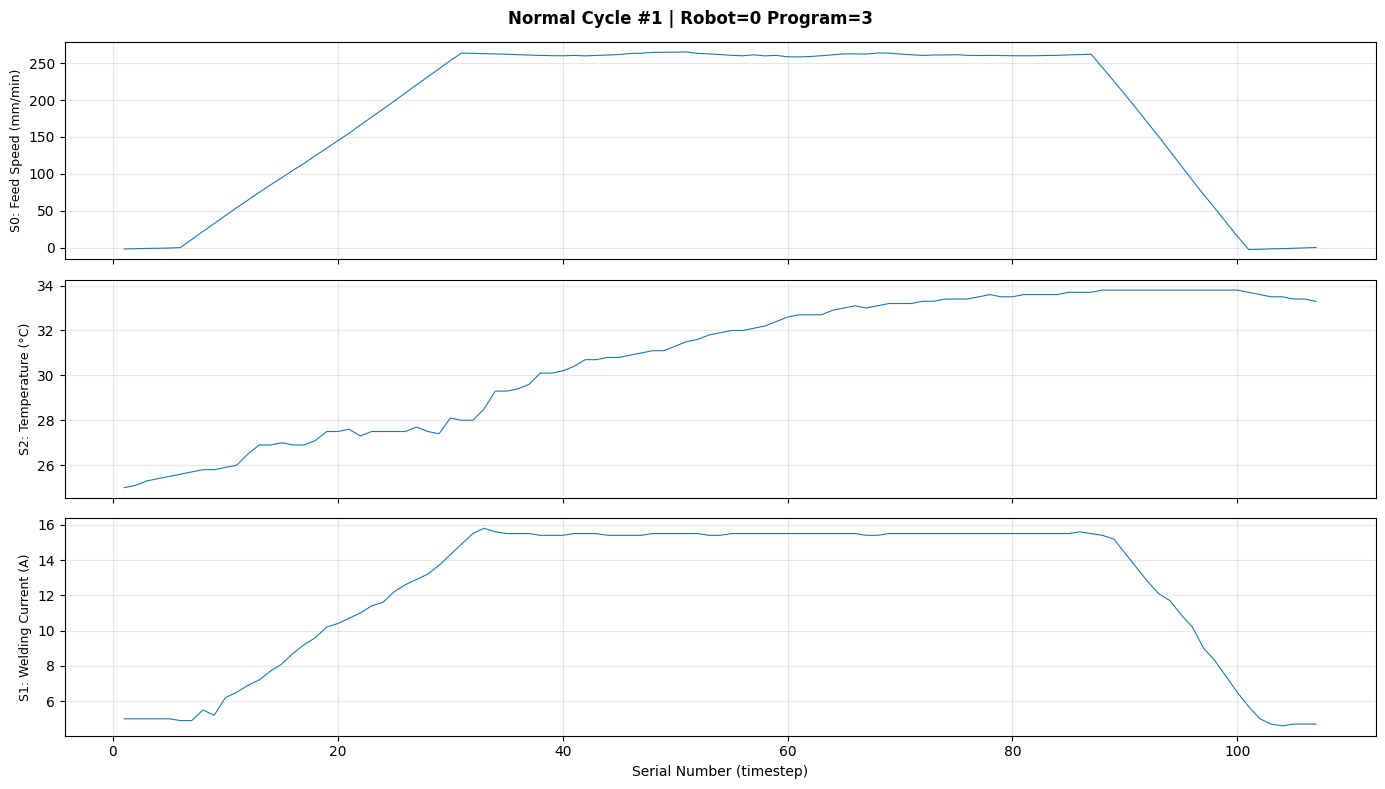

NORMAL SAMPLE (from test data)


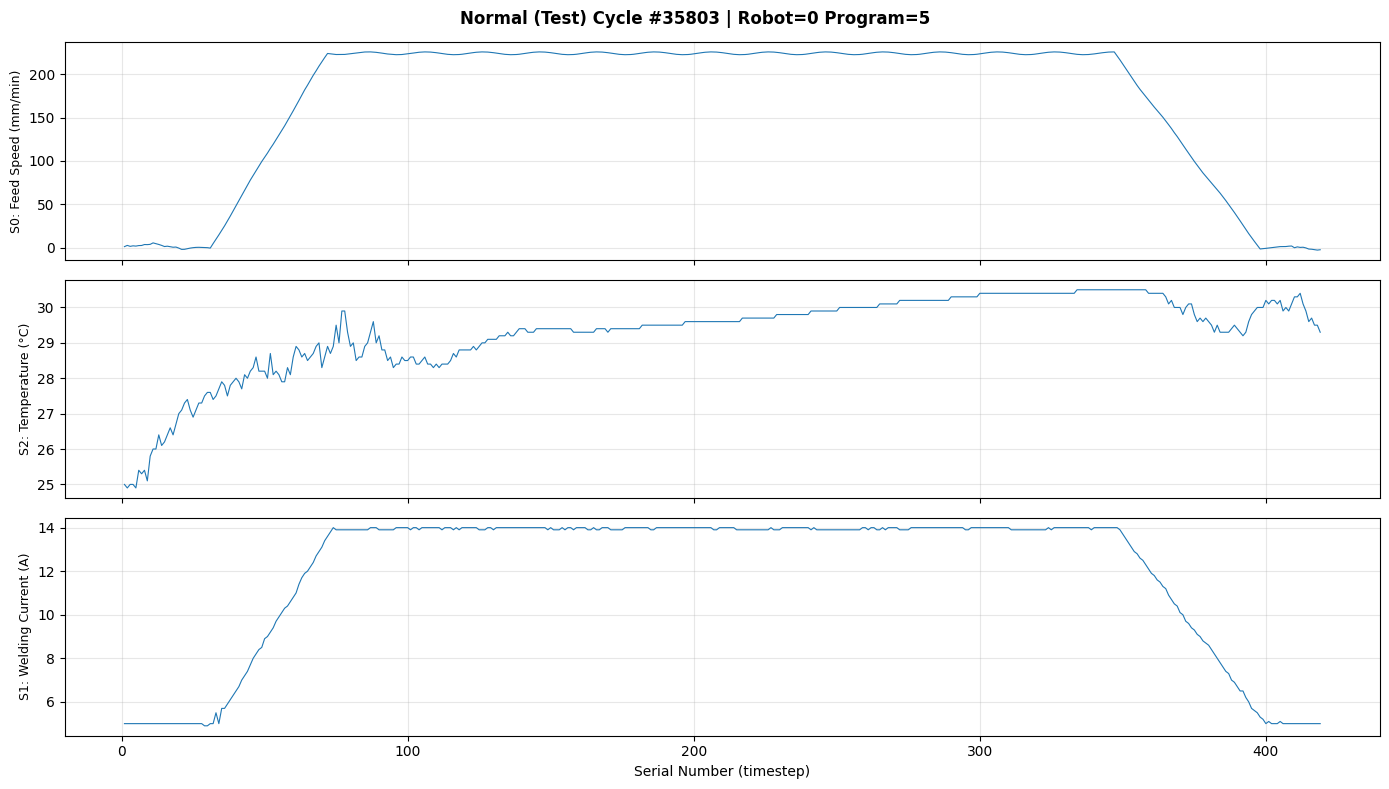

ANOMALY SAMPLES (one per type)


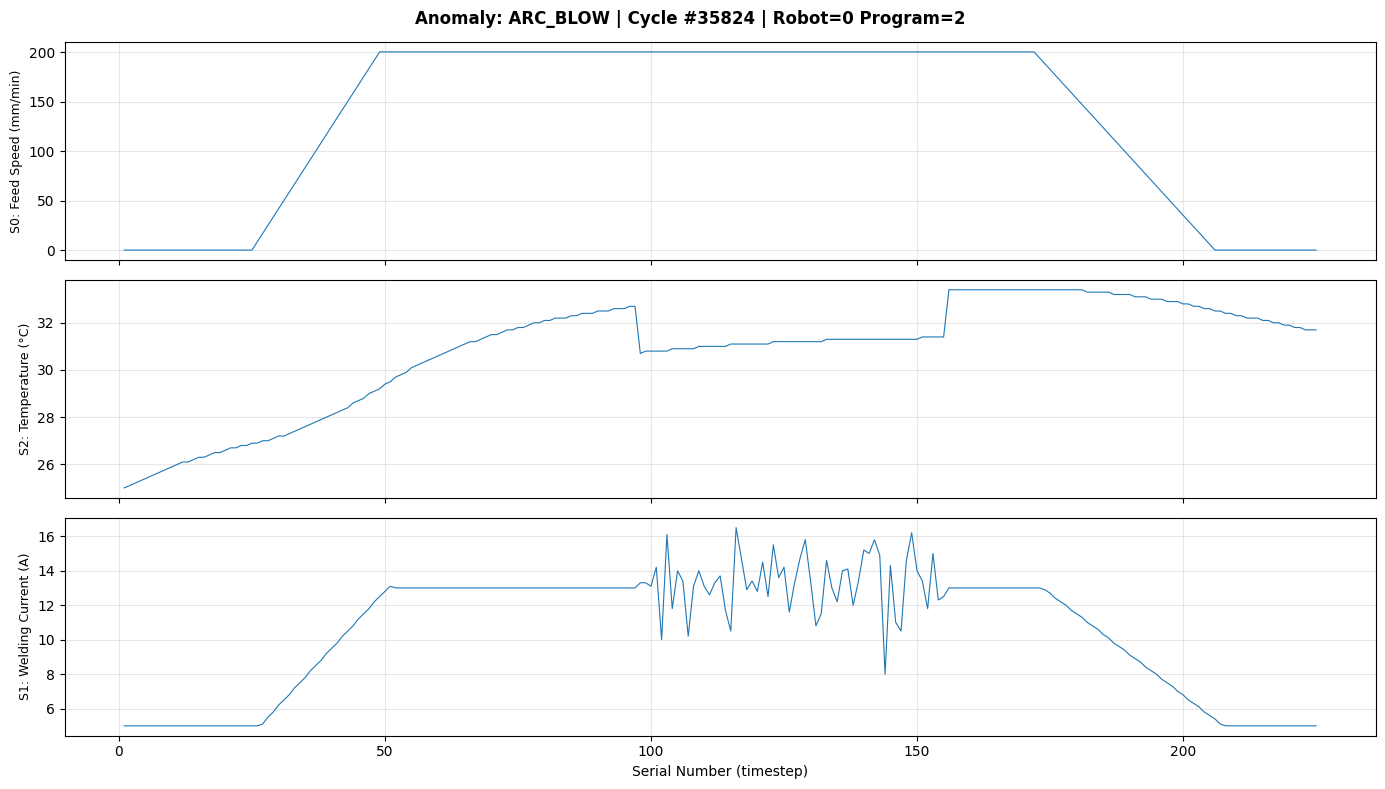

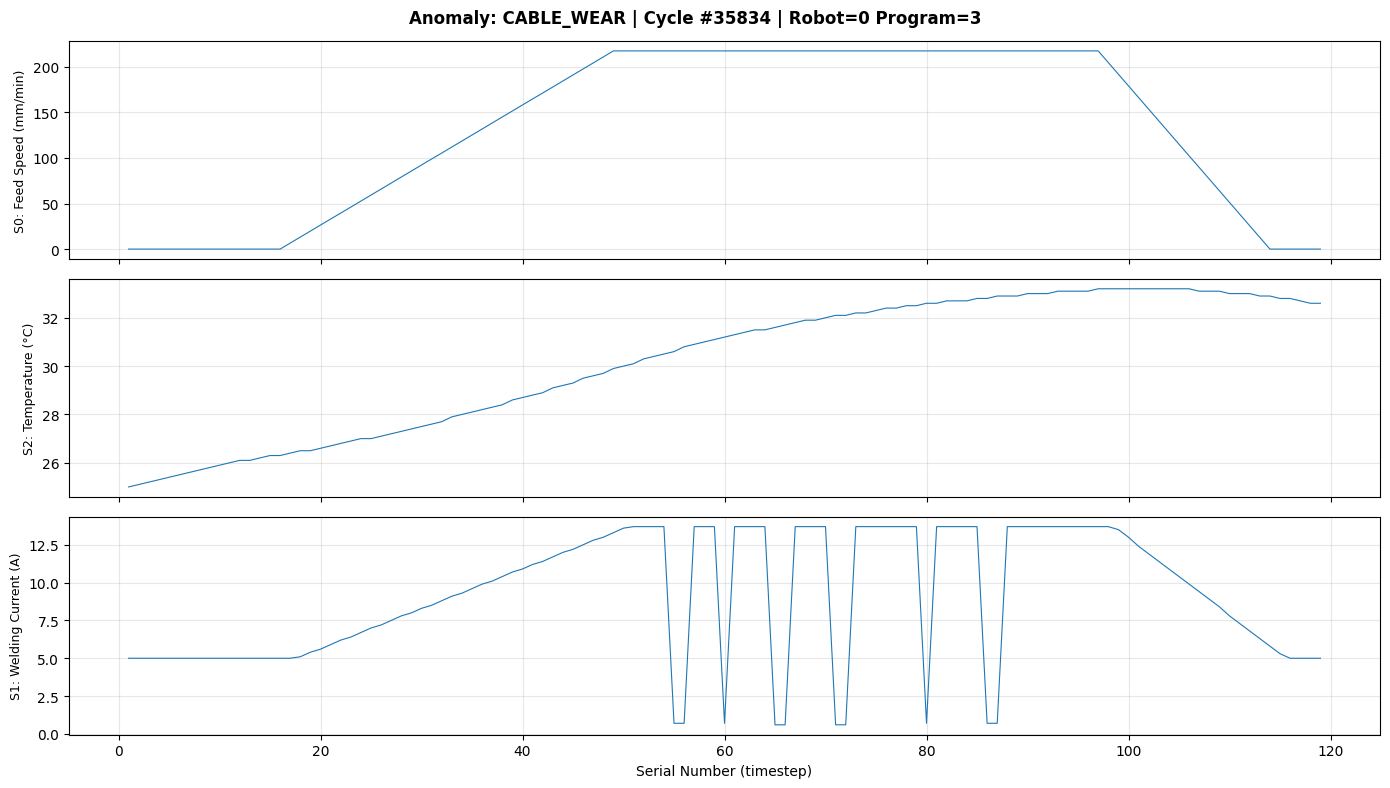

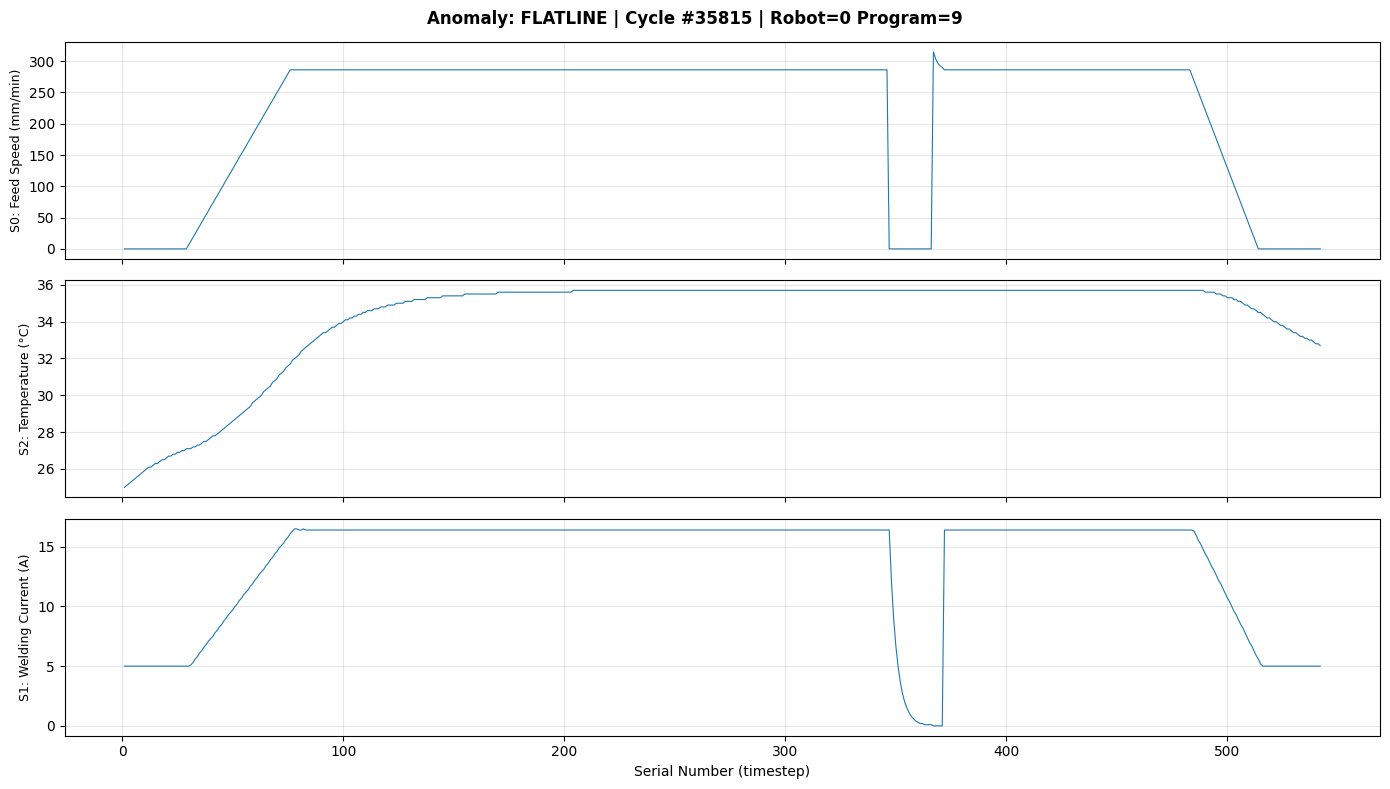

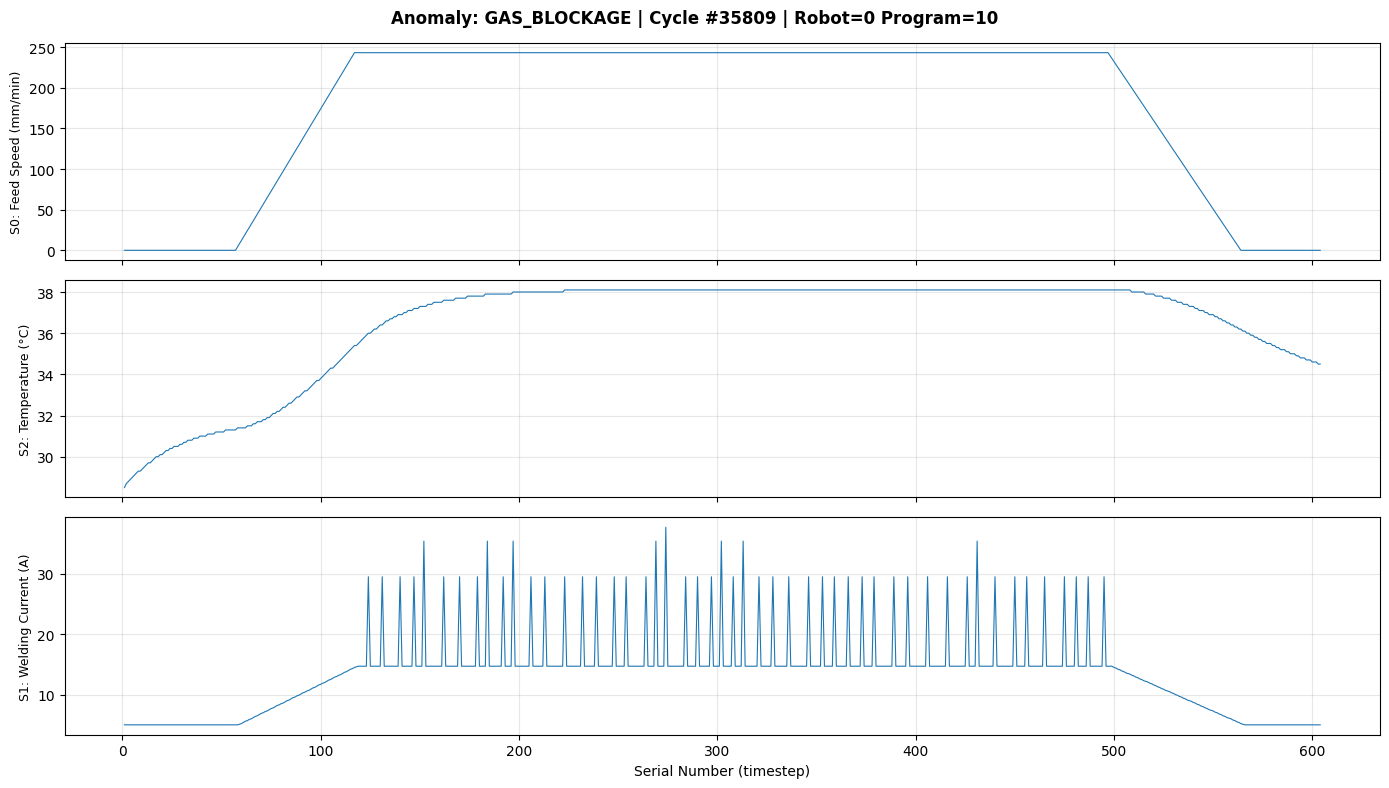

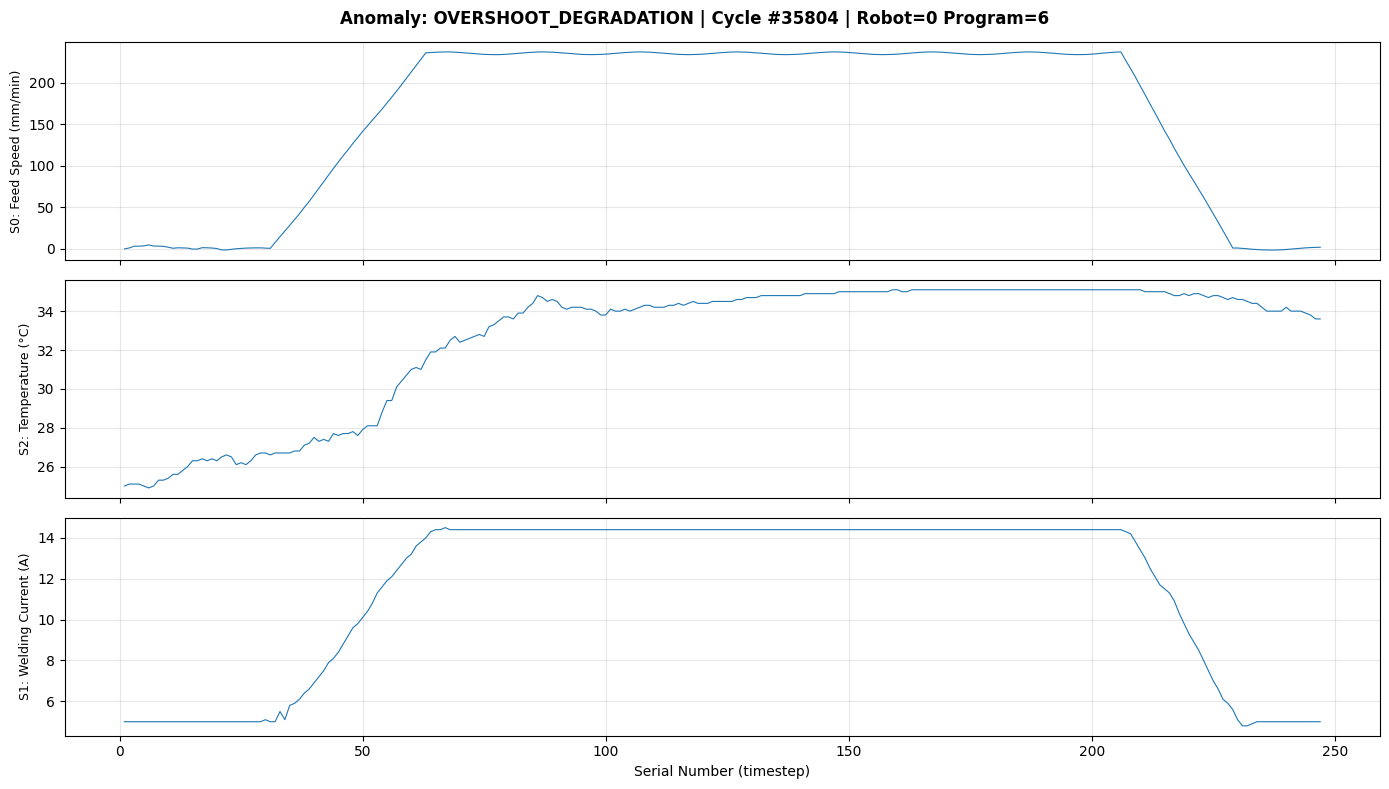

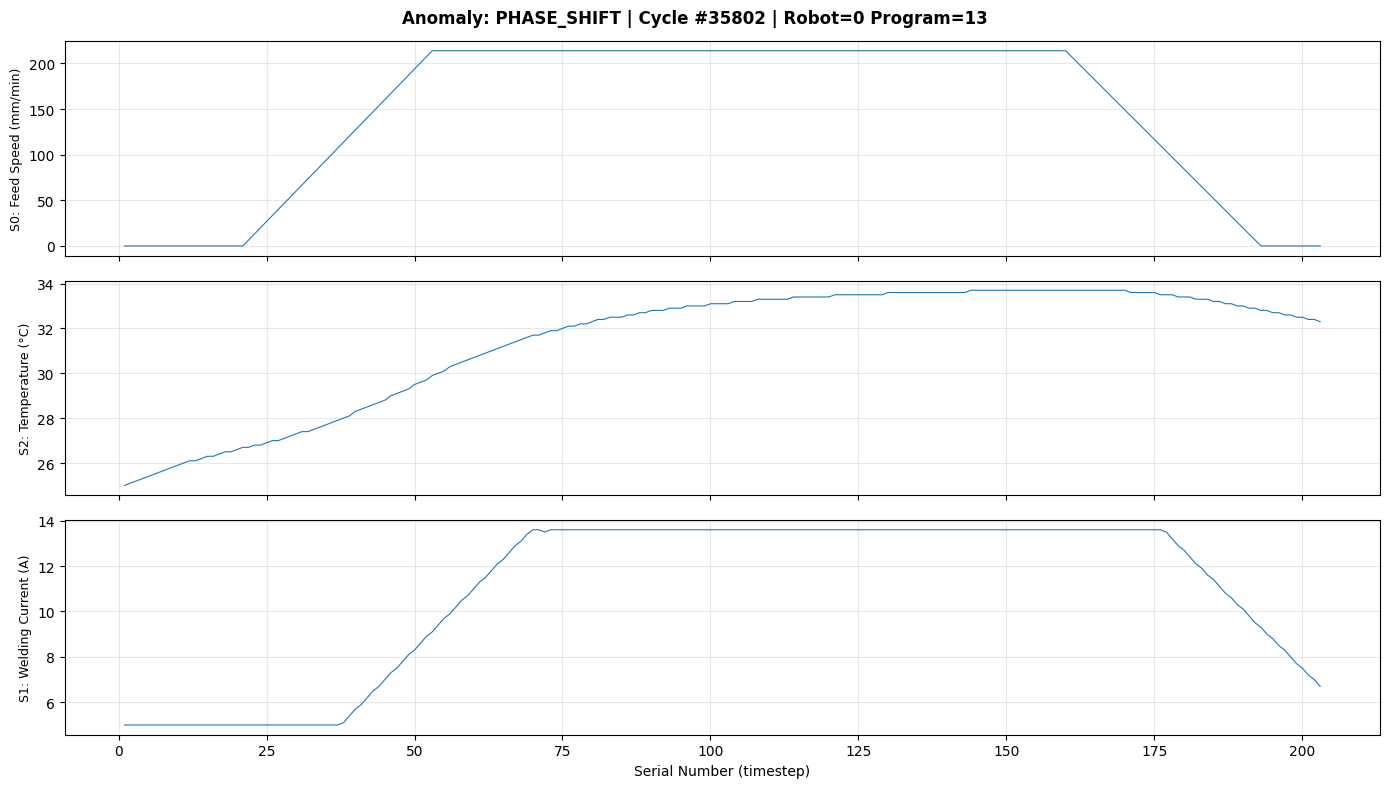

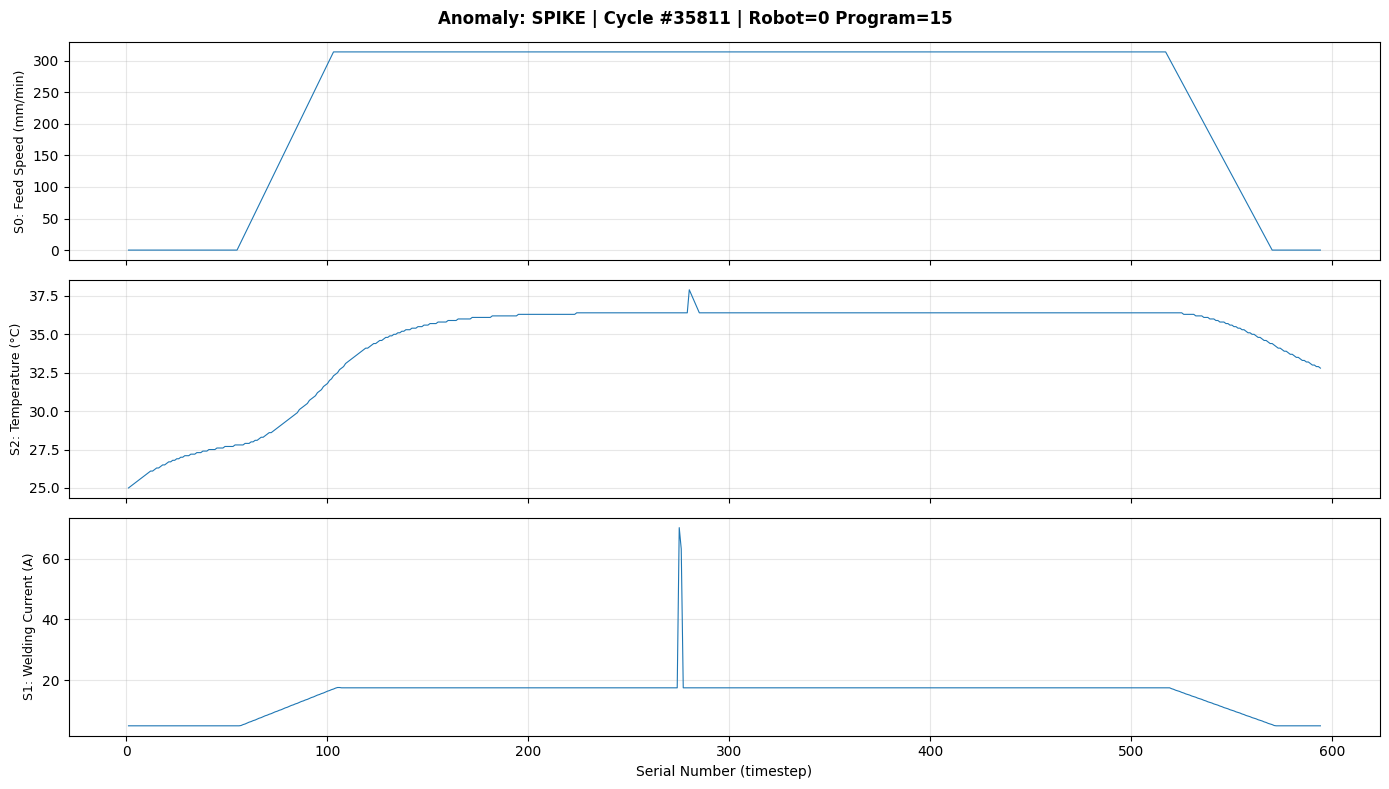

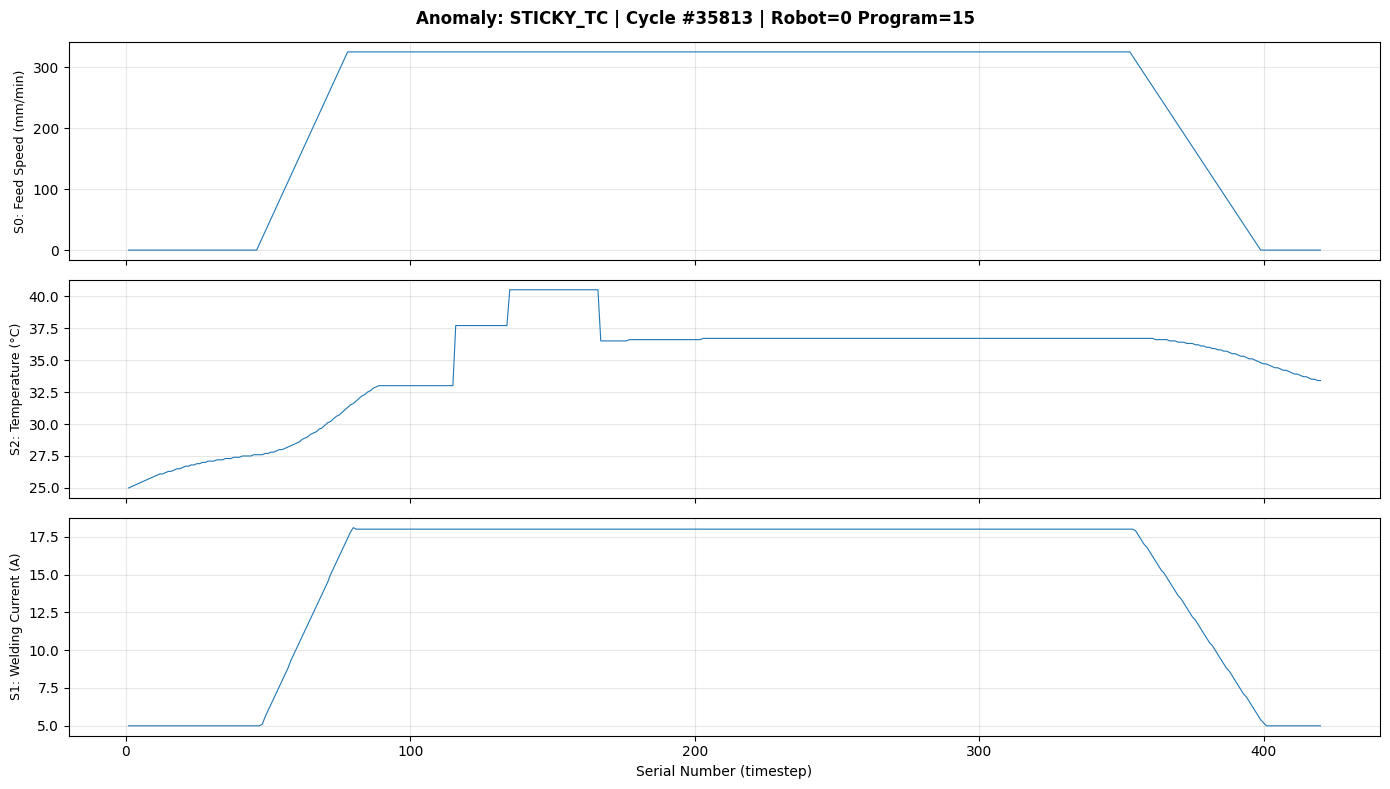

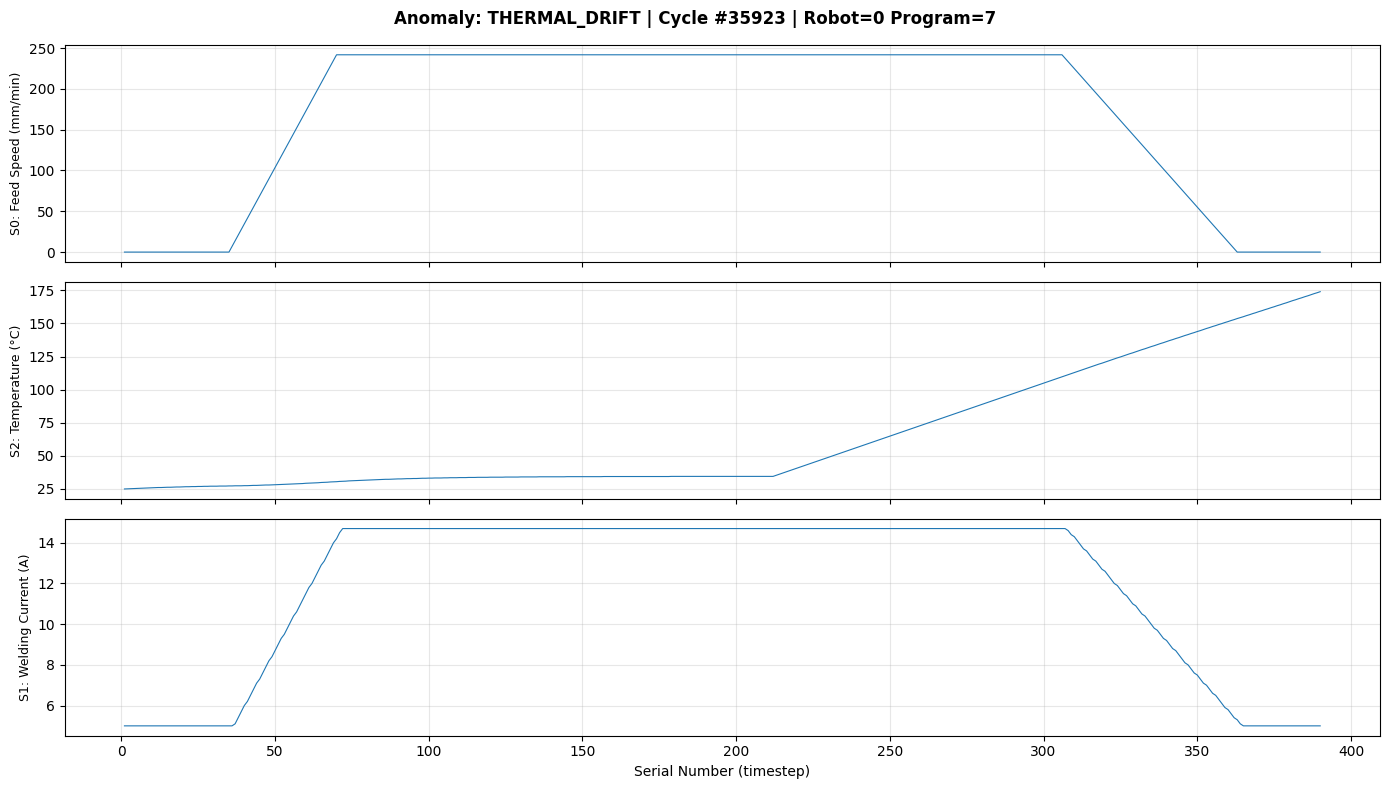

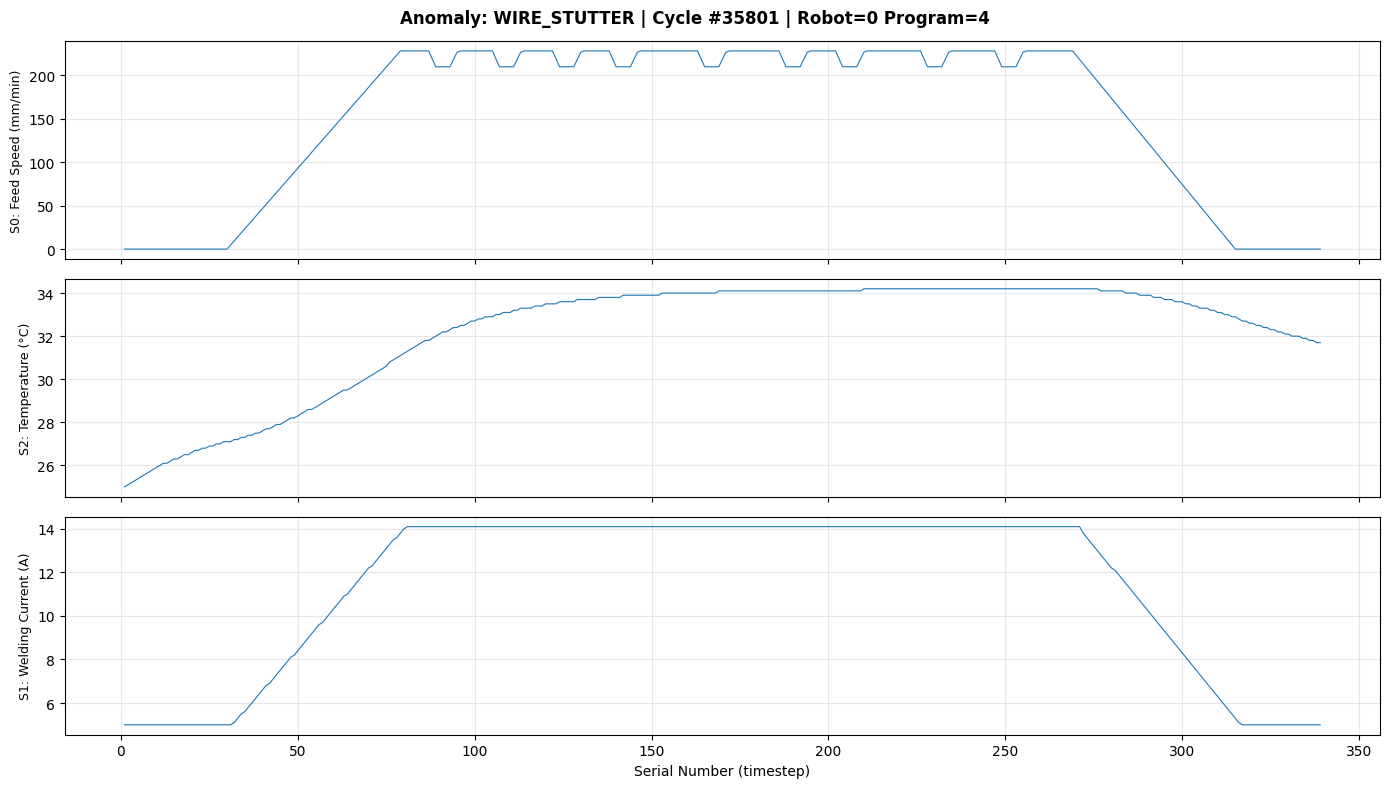

In [5]:
# %% Visualize random samples with metadata
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load data
train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)
test_labels = pd.read_csv(labels_path)

# Merge test labels for anomaly info on test data
test_df = test_df.merge(test_labels[["cycle_id", "anomaly_type"]], on="cycle_id", how="left")
test_df['anomaly_type'] = test_df['anomaly_type_x']
test_df.drop(columns=['anomaly_type_x', 'anomaly_type_y'], inplace=True)

SENSOR_COLS = ["wire_feed_speed_mm_min", "wire_temperature_c", "welding_current_a"]
SENSOR_NAMES = ["S0: Feed Speed (mm/min)", "S2: Temperature (°C)", "S1: Welding Current (A)"]

def plot_cycle(cycle_df, title=""):
    """Plot 3 sensors for one welding cycle."""
    fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
    for ax, col, name in zip(axes, SENSOR_COLS, SENSOR_NAMES):
        ax.plot(cycle_df["serial_number"], cycle_df[col], linewidth=0.8)
        ax.set_ylabel(name, fontsize=9)
        ax.grid(True, alpha=0.3)
    axes[-1].set_xlabel("Serial Number (timestep)")
    fig.suptitle(title, fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()

# --- Show one normal training sample ---
print("=" * 60)
print("NORMAL SAMPLE (from training data)")
print("=" * 60)
normal_cycle_id = train_df["cycle_id"].iloc[0]
normal_cycle = train_df[train_df["cycle_id"] == normal_cycle_id]
meta = normal_cycle.iloc[0]
plot_cycle(normal_cycle, 
    f"Normal Cycle #{normal_cycle_id} | Robot={meta['robot_code']} Program={meta['program_number']}")

# --- Show one normal test sample ---
print("=" * 60)
print("NORMAL SAMPLE (from test data)")
print("=" * 60)
normal_test = test_df[test_df["anomaly_type"] == "normal"]
if len(normal_test) > 0:
    cid = normal_test["cycle_id"].iloc[0]
    cycle = test_df[test_df["cycle_id"] == cid]
    meta = cycle.iloc[0]
    plot_cycle(cycle,
        f"Normal (Test) Cycle #{cid} | Robot={meta['robot_code']} Program={meta['program_number']}")

# --- Show one cycle of each anomaly type ---
print("=" * 60)
print("ANOMALY SAMPLES (one per type)")
print("=" * 60)
anomaly_types = [t for t in test_df["anomaly_type"].unique() if t != "normal"]
for anom_type in sorted(anomaly_types):
    subset = test_df[test_df["anomaly_type"] == anom_type]
    if len(subset) == 0:
        continue
    cid = subset["cycle_id"].iloc[0]
    cycle = test_df[test_df["cycle_id"] == cid]
    meta = cycle.iloc[0]
    plot_cycle(cycle,
        f"Anomaly: {anom_type.upper()} | Cycle #{cid} | "
        f"Robot={meta['robot_code']} Program={meta['program_number']}")
